# Axe 12 (bonus) : prédire la faillite

**Bonus, hors programme du cours.** On construit un modèle qui estime, à partir des comptes d'une entreprise et de son profil, le risque d'**entrée en défaillance dans les 36 mois** après la clôture des comptes (`faillite_36_mois` dans `panel_exercices`).

### Lexique

| Terme | En clair |
|---|---|
| **Classification supervisée** | On apprend à partir d'exemples dont on connaît la réponse (faillite ou non), puis on prédit pour de nouveaux exemples. |
| **Apprentissage / test** | On apprend sur une partie des données et on mesure la qualité sur une autre partie, jamais vue pendant l'apprentissage. |
| **Classes déséquilibrées** | Seulement 1,9 % des exercices sont suivis d'une faillite. Un modèle qui répond toujours « non » aurait 98 % de bonnes réponses, et ne servirait à rien. |
| **AUC (courbe ROC)** | La probabilité que le modèle donne un risque plus élevé à une entreprise qui fera faillite qu'à une qui ne fera pas faillite. 0,5 = hasard, 1 = parfait. |
| **Précision moyenne (AP)** | Résume le compromis précision / rappel. Avec 2 % de faillites, le hasard donne environ 0,02. |
| **Rappel / précision** | Parmi les faillites, combien on en détecte (rappel). Parmi les alertes, combien sont justes (précision). |
| **Importance par permutation** | On mélange une variable au hasard et on regarde de combien la qualité baisse : plus elle baisse, plus la variable compte. |

### Les décisions

| Sujet | Décision | Qui |
|---|---|---|
| Découpage | Apprentissage sur les comptes clôturés en **2016-2020**, test sur **2021-2023** : on prédit « l'avenir », comme dans un vrai usage. | Luka |
| Variables | Les 13 ratios de l'axe 10, le chiffre d'affaires (log), l'âge, la section NAF, la famille juridique, `deja_defaillante`, et le nombre de valeurs ramenées par la winsorisation. Les valeurs manquantes sont gardées (le modèle à arbres sait les gérer, la régression logistique reçoit la médiane + un indicateur « manquant »). | Luka |
| Déséquilibre | **Pondération des classes** (`class_weight="balanced"`) plutôt que de supprimer des exemples. Pour la RAM, on garde toutes les faillites et 20 % des autres exercices pour l'apprentissage, en corrigeant les poids. | Luka |
| Modèles | Régression logistique et arbre de décision (lisibles), puis gradient boosting (plus puissant). | Luka |

## 1. Chargement

In [1]:
import sys
sys.path.append("../../scripts")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text
from data_utils import PROCESSED, free_memory, mem
import graphe_utils as gu

DASH = PROCESSED.parent / "dashboard"
RATIOS = ["taux_d_endettement", "ratio_de_liquidite", "ratio_de_vetuste", "autonomie_financiere",
          "couverture_des_interets", "caf_sur_ca", "capacite_de_remboursement", "marge_ebe",
          "resultat_courant_avant_impots_sur_ca", "poids_bfr_exploitation_sur_ca_jours",
          "rotation_des_stocks_jours", "credit_clients_jours", "credit_fournisseurs_jours"]
RAMENE = [c + "_ramene" for c in RATIOS + ["chiffre_d_affaires"]]
p = pd.read_parquet(PROCESSED / "panel_exercices.parquet",
                    columns=["siren", "date_cloture_exercice", *RATIOS, "chiffre_d_affaires", *RAMENE,
                             "age_ans", "naf_section", "cj_famille", "deja_defaillante", "faillite_36_mois"])
p["log_ca"] = np.log1p(p["chiffre_d_affaires"].clip(lower=0))
p["valeurs_ramenees"] = p[RAMENE].sum(axis=1)
p = p.drop(columns=RAMENE + ["chiffre_d_affaires"])
for c in ["naf_section", "cj_famille"]:
    p[c] = p[c].astype("string").fillna("inconnu")
p["annee"] = p["date_cloture_exercice"].dt.year
print(len(p), "exercices |", mem())
p.groupby("annee")["faillite_36_mois"].agg(["size", "mean"]).rename(columns={"size": "exercices", "mean": "taux de faillite"}).round(4)

5057975 exercices | process : 1.89 Go | disponible : 4.82 Go


,exercices,taux de faillite
annee,,
2016,669811,0.0234
2017,719754,0.0182
2018,698664,0.0136
2019,700768,0.0131
2020,690253,0.0180
2021,683861,0.0224
2022,676180,0.0238
2023,218684,0.0226


### Observations

- Le taux de faillite dans les 36 mois varie selon l'année de clôture : de **1,3 %** (comptes 2019, dont les 36 mois tombent pendant le Covid) à **2,4 %** (comptes 2022). Les années de test (2021-2023) ont un taux plus élevé que la moyenne de l'apprentissage.

## 2. Apprentissage (2016-2020) et test (2021-2023)

In [2]:
NUM = RATIOS + ["log_ca", "age_ans", "valeurs_ramenees"]
CAT = ["naf_section", "cj_famille"]
VARIABLES = NUM + CAT + ["deja_defaillante"]

rng = np.random.default_rng(0)
app = p[p["annee"] <= 2020]
test = p[p["annee"] >= 2021]
garde = app["faillite_36_mois"] | (rng.random(len(app)) < 0.20)
app = app[garde]
# Chaque exercice « sans faillite » gardé en représente 5 : on le compte 5 fois, puis on équilibre les classes
poids_brut = np.where(app["faillite_36_mois"], 1.0, 5.0)
y_app = app["faillite_36_mois"].to_numpy()
poids = poids_brut * np.where(y_app, poids_brut[~y_app].sum() / poids_brut[y_app].sum(), 1.0)
test = test.sample(400_000, random_state=0) if len(test) > 400_000 else test
y_test = test["faillite_36_mois"].to_numpy()
del p
free_memory()
print(f"apprentissage : {len(app):,} exercices ({y_app.mean():.1%} de faillites dans l'échantillon)"
      f" | test : {len(test):,} ({y_test.mean():.2%} de faillites) | {mem()}".replace(",", " "))

apprentissage : 743 810 exercices (8.0% de faillites dans l'échantillon) | test : 400 000 (2.27% de faillites) | process : 0.63 Go | disponible : 6.08 Go


### Observations

- L'apprentissage garde **743 810 exercices** (toutes les faillites et 20 % des autres), avec 8 % de faillites dans l'échantillon. Le test garde **400 000 exercices** de 2021-2023, avec la vraie proportion de faillites (**2,27 %**).

## 3. Trois modèles

In [3]:
prep_lin = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
    ("bool", "passthrough", ["deja_defaillante"]),
])
logit = make_pipeline(prep_lin, LogisticRegression(max_iter=2000, C=1.0))
# Pour l'arbre : pas de centrage-réduction, pour que les seuils restent lisibles (en %, en jours, en années)
prep_arbre = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
    ("bool", "passthrough", ["deja_defaillante"]),
], verbose_feature_names_out=False)
arbre = make_pipeline(prep_arbre, DecisionTreeClassifier(max_depth=4, min_samples_leaf=500, random_state=0))
X_app = app[VARIABLES].assign(deja_defaillante=app["deja_defaillante"].astype(int))
X_test = test[VARIABLES].assign(deja_defaillante=test["deja_defaillante"].astype(int))
for c in CAT:
    X_app[c] = X_app[c].astype("category")
    X_test[c] = pd.Categorical(X_test[c], categories=X_app[c].cat.categories)
boost = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, categorical_features="from_dtype",
                                       random_state=0)
modeles = {"régression logistique": logit, "arbre de décision (profondeur 4)": arbre, "gradient boosting": boost}
scores, probas = [], {}
for nom, m in modeles.items():
    m.fit(X_app, y_app, **({"logisticregression__sample_weight": poids} if nom.startswith("rég") else
                           {"decisiontreeclassifier__sample_weight": poids} if nom.startswith("arbre") else
                           {"sample_weight": poids}))
    probas[nom] = m.predict_proba(X_test)[:, 1]
    alerte = probas[nom] >= np.quantile(probas[nom], 0.90)   # on alerte sur les 10 % les plus risqués
    scores.append({"modèle": nom, "AUC": roc_auc_score(y_test, probas[nom]),
                   "précision moyenne (AP)": average_precision_score(y_test, probas[nom]),
                   "rappel (top 10 %)": y_test[alerte].sum() / y_test.sum(),
                   "précision (top 10 %)": y_test[alerte].mean()})
scores = pd.DataFrame(scores).set_index("modèle")
scores.loc["hasard"] = [0.5, y_test.mean(), 0.10, y_test.mean()]
scores.round(3)

,AUC,précision moyenne (AP),rappel (top 10 %),précision (top 10 %)
modèle,,,,
régression logistique,0.721,0.052,0.292,0.066
arbre de décision (profondeur 4),0.753,0.067,0.410,0.074
gradient boosting,0.832,0.120,0.479,0.109
hasard,0.500,0.023,0.100,0.023


### Observations

- Les trois modèles font bien mieux que le hasard. Le **gradient boosting** est le meilleur : **AUC 0,83**. L'arbre de décision (0,75) et la régression logistique (0,72) sont derrière.
- En alertant sur les **10 % d'exercices les plus risqués**, le gradient boosting repère **48 %** des faillites (rappel), contre 10 % au hasard. Mais **1 alerte sur 9** seulement est une vraie faillite (précision 10,9 %) : avec 2 % de faillites, il y a forcément beaucoup de fausses alertes.
- La précision moyenne (0,12) reste basse dans l'absolu, mais elle est **5 fois** celle du hasard (0,023).

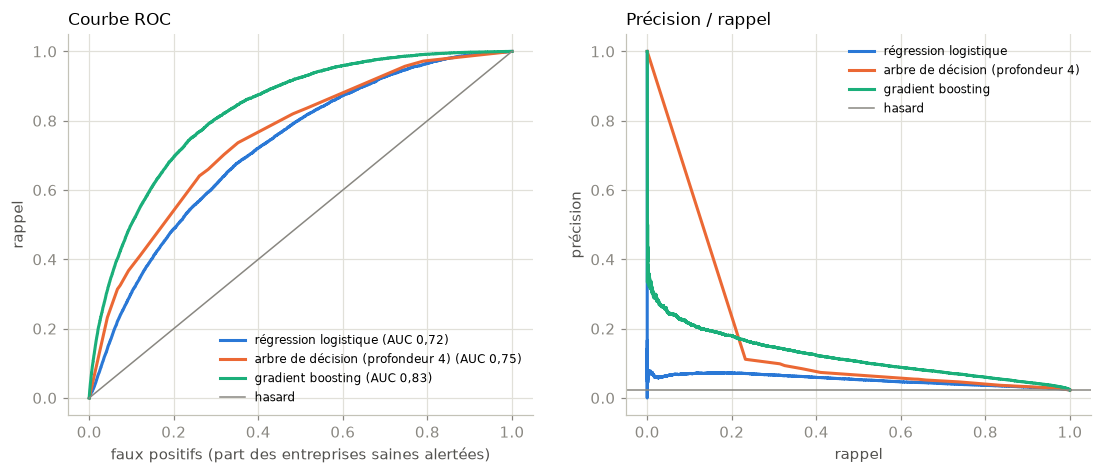

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for (nom, pr), c in zip(probas.items(), gu.COULEURS):
    fpr, tpr, _ = roc_curve(y_test, pr)
    axes[0].plot(fpr, tpr, color=c, lw=2, label=f"{nom} (AUC {roc_auc_score(y_test, pr):.2f})".replace(".", ","))
    prec, rap, _ = precision_recall_curve(y_test, pr)
    axes[1].plot(rap, prec, color=c, lw=2, label=nom)
axes[0].plot([0, 1], [0, 1], color=gu.GRIS, lw=1, label="hasard")
axes[0].set_xlabel("faux positifs (part des entreprises saines alertées)"); axes[0].set_ylabel("rappel")
axes[0].set_title("Courbe ROC", loc="left", fontsize=11)
axes[1].axhline(y_test.mean(), color=gu.GRIS, lw=1, label="hasard")
axes[1].set_xlabel("rappel"); axes[1].set_ylabel("précision")
axes[1].set_title("Précision / rappel", loc="left", fontsize=11)
for ax in axes: ax.legend(frameon=False, fontsize=8)
plt.show()

## 4. Que regarde le modèle ?

In [5]:
# L'arbre de décision se lit directement (seuils dans les unités réelles ; class: True = « risque élevé »)
noms = list(arbre[0].get_feature_names_out())
print(export_text(arbre[-1], feature_names=noms, max_depth=4, decimals=1, show_weights=False))

|--- ratio_de_liquidite <= 177.7
|   |--- taux_d_endettement <= -0.0
|   |   |--- log_ca <= 10.4
|   |   |   |--- taux_d_endettement <= -87.9
|   |   |   |   |--- class: True
|   |   |   |--- taux_d_endettement >  -87.9
|   |   |   |   |--- class: True
|   |   |--- log_ca >  10.4
|   |   |   |--- marge_ebe <= 31.4
|   |   |   |   |--- class: True
|   |   |   |--- marge_ebe >  31.4
|   |   |   |   |--- class: False
|   |--- taux_d_endettement >  -0.0
|   |   |--- autonomie_financiere <= 27.5
|   |   |   |--- naf_section_F <= 0.5
|   |   |   |   |--- class: True
|   |   |   |--- naf_section_F >  0.5
|   |   |   |   |--- class: True
|   |   |--- autonomie_financiere >  27.5
|   |   |   |--- resultat_courant_avant_impots_sur_ca <= 0.8
|   |   |   |   |--- class: True
|   |   |   |--- resultat_courant_avant_impots_sur_ca >  0.8
|   |   |   |   |--- class: False
|--- ratio_de_liquidite >  177.7
|   |--- autonomie_financiere <= 50.8
|   |   |--- caf_sur_ca <= 2.5
|   |   |   |--- couverture_d

### Observations

- L'arbre de décision commence par la **liquidité** (seuil 178 %) : c'est la première question qu'il pose.
- Avec une liquidité faible, il regarde l'**endettement** (un endettement négatif veut dire des capitaux propres négatifs), puis l'autonomie financière et le résultat.
- Avec une liquidité correcte, il regarde l'**autonomie financière**, la **CAF**, et l'**âge** (moins de 5 ans = plus risqué).
- Ces seuils ressemblent aux règles classiques de l'analyse financière : peu de trésorerie, des capitaux propres négatifs ou des pertes signalent une entreprise fragile.

In [6]:
# Importance par permutation (gradient boosting), sur 60 000 exercices de test
idx = np.random.default_rng(1).choice(len(X_test), 60_000, replace=False)
imp = permutation_importance(boost, X_test.iloc[idx], y_test[idx], scoring="roc_auc", n_repeats=3, random_state=0)
importance = pd.Series(imp.importances_mean, index=VARIABLES).sort_values(ascending=False)
importance.round(4).to_frame("baisse de l'AUC quand on mélange la variable")

,baisse de l'AUC quand on mélange la variable
ratio_de_liquidite,0.0628
naf_section,0.0300
poids_bfr_exploitation_sur_ca_jours,0.0250
autonomie_financiere,0.0243
taux_d_endettement,0.0228
age_ans,0.0180
log_ca,0.0174
resultat_courant_avant_impots_sur_ca,0.0094
caf_sur_ca,0.0069
capacite_de_remboursement,0.0066


### Observations

- Pour le gradient boosting, la variable la plus importante est de loin la **liquidité** (mélangée, l'AUC baisse de 0,063). Viennent ensuite le **secteur**, le **BFR**, l'**autonomie financière**, l'**endettement**, puis l'**âge** et la **taille** (chiffre d'affaires).
- Les ratios de rentabilité (marge d'EBE, CAF) comptent beaucoup moins, ainsi que `deja_defaillante` et le nombre de valeurs ramenées (presque 0).

In [7]:
# Le score de risque et le taux de faillite réel selon la variable la plus importante, par déciles
# (le score n'est pas une vraie probabilité : la pondération des classes le gonfle ; il sert à classer les entreprises)
top = importance.index[0]
deciles = (pd.qcut(X_test[top].rank(method="first"), 10, labels=False) + 1).astype("Int64").to_numpy()
t = pd.DataFrame({"décile": deciles, "valeur": X_test[top].to_numpy(), "score": probas["gradient boosting"], "faillite": y_test})
t.groupby("décile").agg(**{f"{top} (médiane)": ("valeur", "median"), "score moyen": ("score", "mean"),
                           "taux de faillite réel (%)": ("faillite", lambda x: 100 * x.mean())}).round(2)

,ratio_de_liquidite (médiane),score moyen,taux de faillite réel (%)
décile,,,
1.0,20.110001,0.44,3.95
2.0,89.040001,0.51,5.21
3.0,125.349998,0.45,4.03
4.0,158.660004,0.38,2.78
5.0,194.729996,0.31,2.09
6.0,239.289993,0.25,1.53
7.0,303.170013,0.21,1.21
8.0,419.010010,0.18,0.97
9.0,753.650024,0.15,0.76


### Observations

- Le taux de faillite réel **baisse avec la liquidité** : **5,2 %** pour le 2e décile (liquidité médiane 89 %), **0,36 %** pour le 10e (liquidité médiane 4 321 %). Le score du modèle suit le même ordre.
- Le 1er décile (liquidité très faible, 20 %) a un peu moins de faillites que le 2e (3,95 % contre 5,21 %) : la relation n'est pas tout à fait régulière aux extrêmes.
- ⚠️ Le score moyen (0,09 à 0,51) n'est **pas** une probabilité de faillite : la pondération des classes le gonfle. Il sert à **classer** les entreprises de la plus à la moins risquée.

## 5. Export pour le dashboard

In [8]:
scores.reset_index().to_parquet(DASH / "prediction_scores.parquet", index=False)
importance.rename_axis("variable").reset_index(name="importance").to_parquet(DASH / "prediction_importance.parquet", index=False)
courbes = []
for nom, pr in probas.items():
    fpr, tpr, _ = roc_curve(y_test, pr)
    pas = max(1, len(fpr) // 300)
    courbes.append(pd.DataFrame({"modele": nom, "faux_positifs": fpr[::pas], "rappel": tpr[::pas]}))
pd.concat(courbes).to_parquet(DASH / "prediction_roc.parquet", index=False)
print("export : prediction_scores, prediction_importance, prediction_roc")

export : prediction_scores, prediction_importance, prediction_roc
